# 02 – Baselines et modèles d'ensemble
Prédire la gravité maximale d'un accident (`grav_max`, **3 classes** : `leger` / `hospitalise` / `tue`) à partir des 20 features construites (voir `01_exploration.ipynb` et le README).

**Ce notebook reprend exactement la préparation du notebook 1** :
- même fichier (`data/processed/accidents_2023.csv`, ou son URL GitHub brute) et mêmes types ;
- **même test set** : 20 % stratifiés sur `grav_max`, `random_state=42`. Il n'est utilisé qu'à la toute fin ;
- mêmes choix d'imputation (section 2 du notebook 1) et d'encodage (one-hot, standardisation).

**Différence importante avec le notebook 1** : là-bas, l'imputation était ajustée une fois sur tout le train pour l'explorer. Ici, **toutes les transformations sont dans un `Pipeline`** : à chaque fold de validation croisée, médianes, modes, moyennes et écarts-types sont réappris sur la partie entraînement du fold uniquement, sans fuite vers la partie validation.

In [1]:
# Imports (une seule cellule). Versions testées : Python 3.9, scikit-learn 1.6, pandas 2.3, seaborn 0.13.
# Sur Colab, tout est déjà installé.
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import make_pipeline as make_pipeline_imb
from imblearn.under_sampling import RandomUnderSampler
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, make_scorer, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 60)
# Faux avertissements « ... encountered in matmul » de numpy avec la bibliothèque de calcul de macOS
# (résultats corrects, rien sur Colab). La variable d'environnement couvre les processus parallèles (n_jobs=-1).
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
# Avertissements de dépréciation dus à imbalanced-learn 0.12 avec scikit-learn 1.6 (sans effet sur les résultats)
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["PYTHONWARNINGS"] = ",".join([f"ignore:{m} encountered in matmul:RuntimeWarning"
                                         for m in ["divide by zero", "overflow", "invalid value"]] + ["ignore::FutureWarning"])
YEAR = 2023
LOCAL = Path("../data/processed") / f"accidents_{YEAR}.csv"
URL = f"https://raw.githubusercontent.com/cyannure/aaa/main/data/processed/accidents_{YEAR}.csv"
SEED = 42
CLASSES = ["leger", "hospitalise", "tue"]
# Séquentiel bleu (clair = faible, foncé = fort), comme dans le notebook 1
# Une couleur fixe par modèle (identités sans ordre), dans le même ordre sur tous les graphes
COULEURS_MODELES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLEUS = LinearSegmentedColormap.from_list("bleus", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#0d366b"])

## 1. Chargement des données
**Cible : 3 classes** (décision d'équipe) : `leger` / `hospitalise` / `tue` (64 / 30 / 6 %).

Les 4 colonnes de contexte (`jour_semaine`, `dep`, `lat`, `long`) ne sont pas des features : on les retire dès le chargement.

In [2]:
CAT = ["lum", "atm", "agg", "int", "col", "catr", "surf", "situ", "veh_vulnerable"]
BIN = ["week_end", "choc_avant", "manv_risquee", "pieton_heurte"]
NUM = ["heure", "vma", "nbv", "age_cond_max", "part_cond_hommes", "part_cond_loisirs", "part_cond_proteges"]
INFO = ["jour_semaine", "dep", "lat", "long"]
TARGET = "grav_max"

df = pd.read_csv(LOCAL if LOCAL.exists() else URL, dtype={c: str for c in CAT + ["dep"]})
df = df.drop(columns=[c for c in INFO if c in df.columns])
df[CAT] = df[CAT].astype("category")

# Même découpage que le notebook 1 (stratifié sur la cible), donc exactement le même test set
train, test = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=SEED)
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]

print(f"train : {X_train.shape}, test : {X_test.shape}, {X_train.shape[1]} features")
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).loc[CLASSES].round(3)

train : (43857, 20), test : (10965, 20), 20 features


,train,test
grav_max,,
leger,0.639,0.639
hospitalise,0.302,0.302
tue,0.058,0.058


## 2. Préparation : feature engineering et pipeline de prétraitement
### 2.1 Nouvelles variables
- **`heure` → `heure_sin`, `heure_cos`** : l'effet de l'heure est cyclique (section 4 du notebook 1 : 23 h ressemble à 0 h, pas à 12 h). Avec un seul nombre, un modèle linéaire voit 23 et 0 aux deux extrémités ; avec le sinus et le cosinus, les heures sont placées sur un cercle.

Transformation ligne par ligne, sans rien apprendre des données : elle peut s'appliquer avant le pipeline sans risque de fuite. D'autres variables (interactions, `vma` en catégories pour les modèles linéaires…) seront testées dans la partie « modèles améliorés ».

In [3]:
def ajouter_features(X):
    X = X.copy()
    angle = 2 * np.pi * X["heure"] / 24
    X["heure_sin"], X["heure_cos"] = np.sin(angle), np.cos(angle)
    return X.drop(columns="heure")

X_train_fe, X_test_fe = ajouter_features(X_train), ajouter_features(X_test)
NUM_FE = [c for c in NUM if c != "heure"] + ["heure_sin", "heure_cos"]
X_train_fe[["heure_sin", "heure_cos"]].describe().loc[["min", "max"]].round(2)

,heure_sin,heure_cos
min,-1.0,-1.0
max,1.0,1.0


### 2.2 Pipeline de prétraitement (le même pour tous les modèles)
Dans l'ordre :
1. **`vma`** : médiane selon `agg` (80 km/h hors agglomération, 50 en agglomération) + indicateur `vma_manquant` (classe `ImputeurParGroupe`, identique au notebook 1).
2. **Numériques** : médiane, puis **standardisation** (moyenne 0, écart-type 1). Nécessaire pour la régression logistique régularisée (la pénalité porte sur la taille des coefficients, qui dépend de l'échelle) ; sans effet sur les arbres, mais on garde le même prétraitement pour comparer les modèles à préparation égale.
3. **Indicateurs de manquants** des 5 numériques concernées : **laissés en 0/1, non standardisés**. Standardiser une colonne 0/1 rare la gonfle artificiellement (vu au clustering du notebook 1).
4. **Catégorielles** : valeur la plus fréquente, puis **one-hot** (une colonne 0/1 par modalité ; `handle_unknown="ignore"` si une modalité rare n'apparaît pas dans un fold).
5. **Binaires** : telles quelles.

In [4]:
class ImputeurParGroupe(BaseEstimator, TransformerMixin):
    """Remplace les NaN de `col` par la médiane de `col` dans le groupe `by`, apprise au fit,
    et ajoute l'indicateur `<col>_manquant`. (Identique au notebook 1.)"""
    def __init__(self, col="vma", by="agg"):
        self.col, self.by = col, by

    def fit(self, X, y=None):
        self.medianes_ = X.groupby(self.by, observed=True)[self.col].median()
        self.mediane_globale_ = X[self.col].median()  # si le groupe est inconnu
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = X.copy()
        manquant = X[self.col].isna()
        valeur_du_groupe = X[self.by].astype(object).map(self.medianes_).astype(float)
        X[self.col] = X[self.col].fillna(valeur_du_groupe).fillna(self.mediane_globale_)
        X[f"{self.col}_manquant"] = manquant.astype(int)
        return X

    def get_feature_names_out(self, input_features=None):
        return np.append(self.feature_names_in_, f"{self.col}_manquant")

NUM_AVEC_NA = ["nbv", "age_cond_max", "part_cond_hommes", "part_cond_loisirs", "part_cond_proteges"]

def preprocesseur():
    """Nouveau prétraitement non ajusté (à mettre en tête de chaque pipeline de modèle)."""
    colonnes = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_FE),
        ("manquant", MissingIndicator(features="all"), NUM_AVEC_NA),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), CAT),
        ("bin", "passthrough", BIN + ["vma_manquant"]),
    ])
    return make_pipeline(ImputeurParGroupe("vma", "agg"), colonnes)

# Vérification sur le train complet
Xp = preprocesseur().fit_transform(X_train_fe)
print("Après prétraitement :", Xp.shape, "| NaN restants :", int(np.isnan(Xp).sum()))

Après prétraitement : (43857, 78) | NaN restants : 0


## 3. Protocole d'évaluation
- **Validation croisée stratifiée à 5 folds** sur le train (`StratifiedKFold`, mélangé, `random_state=42`), **la même pour tous les modèles** du notebook. Ces 5 folds serviront aussi de boucle externe à la nested CV lors du réglage des hyperparamètres.
- **Mêmes métriques pour tous les modèles.** Les classes sont déséquilibrées : prédire toujours `leger` donne déjà 64 % d'accuracy. On suit donc :
  - **F1 macro** (métrique principale) : moyenne des F1 des 3 classes, chacune pèse autant ;
  - **balanced accuracy** : moyenne des rappels des 3 classes ;
  - **rappel de `tue`** : part des accidents mortels effectivement détectés ;
  - **accuracy**, pour référence.
- Scores sur les folds d'entraînement **et** de validation : un grand écart signale du sur-apprentissage.
- **Rééchantillonnage** (sous- ou sur-échantillonnage, pour les modèles sans `class_weight`) : placé dans un pipeline `imbalanced-learn`, il n'est appliqué **qu'à la partie entraînement de chaque fold**, jamais aux données de validation ni au test (consigne du sujet). Les données de validation gardent donc leurs vraies proportions.

In [5]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRIQUES = {
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "rappel_tue": make_scorer(recall_score, labels=["tue"], average="macro"),
    "accuracy": "accuracy",
}
resultats = {}   # nom du modèle -> scores de chaque fold

def pipeline(modele, reechantillonnage=None):
    """Prétraitement + (rééchantillonnage) + modèle. Pipeline imbalanced-learn : le rééchantillonnage
    n'agit qu'au fit, donc seulement sur la partie entraînement de chaque fold."""
    etapes = [etape for _, etape in preprocesseur().steps]   # mis à plat : imbalanced-learn refuse les pipelines imbriqués
    return make_pipeline_imb(*etapes, *([reechantillonnage] if reechantillonnage else []), modele)

def evaluer(nom, modele, reechantillonnage=None):
    """Validation croisée du pipeline complet, avec les folds et métriques communs à tous les modèles."""
    debut = time.time()
    cv = cross_validate(pipeline(modele, reechantillonnage), X_train_fe, y_train, cv=CV,
                        scoring=METRIQUES, return_train_score=True, n_jobs=-1)
    resultats[nom] = cv
    print(f"{nom} ({time.time() - debut:.0f} s)")
    return pd.DataFrame({"validation": [cv[f"test_{m}"].mean() for m in METRIQUES],
                         "écart-type": [cv[f"test_{m}"].std() for m in METRIQUES],
                         "entraînement": [cv[f"train_{m}"].mean() for m in METRIQUES]},
                        index=list(METRIQUES)).round(3)

def comparer():
    """Même graphique pour tous les modèles évalués jusqu'ici : barres = moyenne en validation (± écart-type),
    points creux = moyenne sur les folds d'entraînement (l'écart mesure le sur-apprentissage)."""
    noms = list(resultats); largeur = 0.8 / len(noms)
    fig, ax = plt.subplots(figsize=(15, 5.5))
    for i, (nom, couleur) in enumerate(zip(noms, COULEURS_MODELES)):
        cv = resultats[nom]
        x = np.arange(len(METRIQUES)) - 0.4 + largeur * (i + 0.5)
        ax.bar(x, [cv[f"test_{m}"].mean() for m in METRIQUES], width=largeur * 0.92, color=couleur, label=nom,
               yerr=[cv[f"test_{m}"].std() for m in METRIQUES], capsize=3)
        ax.scatter(x, [cv[f"train_{m}"].mean() for m in METRIQUES], s=40, facecolor="white", edgecolor=couleur, linewidth=2, zorder=3)
    ax.scatter([], [], s=40, facecolor="white", edgecolor="grey", linewidth=2, label="score sur l'entraînement")
    ax.grid(axis="x", visible=False); ax.set_xticks(range(len(METRIQUES)), list(METRIQUES))
    ax.set(ylim=(0, 1), ylabel="score (validation croisée, 5 folds)", title="Comparaison des modèles")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()
    return pd.DataFrame({nom: {m: resultats[nom][f"test_{m}"].mean() for m in METRIQUES} for nom in noms}).T.round(3)

## 4. Classification multiclasse : One-vs-One (OvO)
Beaucoup de classifieurs (régression logistique binaire, SVM) ne savent séparer que **deux** classes. La stratégie **One-vs-One** ramène le problème à 3 classes à plusieurs problèmes binaires :
- on entraîne **un classifieur par paire de classes**, soit K(K−1)/2 = **3 classifieurs** : `leger` contre `hospitalise`, `leger` contre `tue`, `hospitalise` contre `tue` ;
- chacun n'est entraîné **que sur les accidents de ses deux classes** (par exemple, le classifieur `leger` / `tue` ne voit jamais d'accident `hospitalise`) ;
- pour prédire, chaque classifieur **vote** pour une des deux classes ; la classe qui a le plus de votes l'emporte (en cas d'égalité, la somme des scores de confiance départage).

**Avantages** : chaque sous-problème est plus simple et plus petit. **Inconvénient** : le nombre de classifieurs croît comme K², sans problème ici avec 3 classes. L'alternative, *One-vs-Rest* (un classifieur par classe contre toutes les autres, donc 3 aussi), sera comparée ensuite.

**Classifieur binaire de base : régression logistique régularisée** (pénalité L2, `C = 1`, le sujet interdit les modèles linéaires non régularisés), avec `class_weight="balanced"` : dans chaque paire, les erreurs sur la classe la moins nombreuse coûtent plus cher (essentiel pour la paire `leger` / `tue`, à ≈ 92 / 8 %). Pas de réglage à ce stade : c'est une baseline.

In [6]:
ovo = OneVsOneClassifier(LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))
evaluer("OvO – régression logistique L2", ovo)

OvO – régression logistique L2 (2 s)


,validation,écart-type,entraînement
f1_macro,0.465,0.003,0.470
balanced_accuracy,0.548,0.005,0.556
rappel_tue,0.601,0.018,0.617
accuracy,0.588,0.004,0.592


### Matrice de confusion et scores par classe
Prédictions obtenues par validation croisée (`cross_val_predict`, mêmes 5 folds) : chaque accident du train est prédit par le modèle entraîné **sans** lui. Lignes = vraie classe, colonnes = classe prédite ; chaque ligne est en % de la vraie classe (la diagonale est donc le rappel de chaque classe).

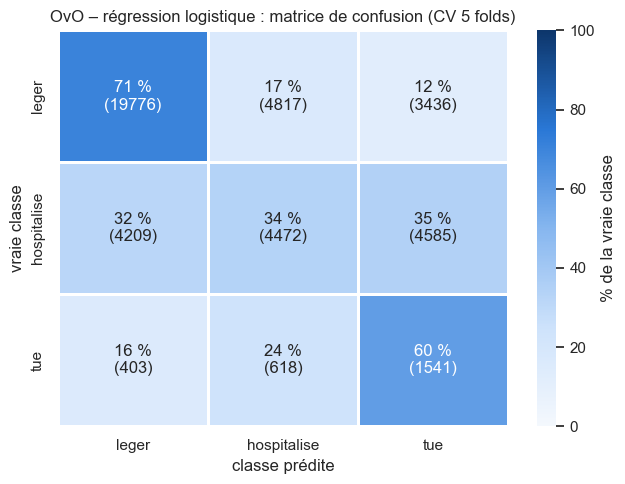

              precision    recall  f1-score   support

       leger      0.811     0.706     0.755     28029
 hospitalise      0.451     0.337     0.386     13266
         tue      0.161     0.601     0.254      2562

    accuracy                          0.588     43857
   macro avg      0.474     0.548     0.465     43857
weighted avg      0.664     0.588     0.614     43857



In [7]:
modele_ovo = pipeline(ovo)
y_pred = cross_val_predict(modele_ovo, X_train_fe, y_train, cv=CV, n_jobs=-1)

mc = confusion_matrix(y_train, y_pred, labels=CLASSES)
mc_pct = pd.DataFrame(mc / mc.sum(axis=1, keepdims=True) * 100, index=CLASSES, columns=CLASSES)
annot = mc_pct.round(0).astype(int).astype(str) + " %\n(" + pd.DataFrame(mc, index=CLASSES, columns=CLASSES).astype(str) + ")"

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(mc_pct, annot=annot, fmt="", cmap=BLEUS, vmin=0, vmax=100, linewidths=2, linecolor="white",
            cbar_kws={"label": "% de la vraie classe"}, ax=ax)
ax.set(xlabel="classe prédite", ylabel="vraie classe", title="OvO – régression logistique : matrice de confusion (CV 5 folds)")
plt.tight_layout(); plt.show()

print(classification_report(y_train, y_pred, labels=CLASSES, digits=3))

**Interprétation de l'OvO avec régression logistique.**
- **Scores** : F1 macro 0,465, balanced accuracy 0,548, **60 % des accidents mortels détectés**. Très au-dessus d'un classifieur naïf (prédire toujours `leger` donne un F1 macro de 0,26 et ne détecte aucun tué).
- **Pas de sur-apprentissage** : scores d'entraînement et de validation quasi identiques (écart < 0,01), et très stables d'un fold à l'autre (écart-type ≤ 0,02). Le modèle est plutôt **trop simple** (sous-apprentissage) : des frontières linéaires ne suffisent pas, ce qui justifie la suite (version polynomiale, ensembles d'arbres).
- **`hospitalise` est la classe la plus difficile** : seulement 34 % bien classés, le reste se répartit à parts presque égales entre `leger` (32 %) et `tue` (35 %). C'est la classe « du milieu », coincée entre les deux autres.
- **Le prix du rappel des tués** : avec `class_weight="balanced"`, le modèle prédit `tue` souvent (≈ 9 600 fois pour 2 562 vrais tués). Sa **précision sur `tue` n'est que de 16 %** : 3 436 accidents légers et 4 585 hospitalisés sont prédits mortels. Selon l'usage (alerter les secours ou non), ce compromis rappel / précision pourra être déplacé en changeant les poids des classes.

## 5. k plus proches voisins (KNN)
**Principe.** Pour classer un accident, on cherche les *k* accidents du train les plus proches (distance euclidienne sur les 78 colonnes prétraitées) et on prend la classe majoritaire parmi eux. Il n'y a pas d'apprentissage à proprement parler : le modèle mémorise le train, et tout le calcul a lieu à la prédiction.

**Ce qui compte pour ce modèle :**
- **Le scaling est indispensable** : la distance additionne les écarts sur chaque colonne. Sans standardisation, `age_cond_max` (de 14 à 99) écraserait tout le reste. C'est fait dans le prétraitement : numériques standardisées, one-hot et binaires en 0/1.
- **Le choix de *k*** règle le compromis biais / variance : *k* = 1 colle au train (sur-apprentissage), un *k* très grand prédit presque toujours la classe majoritaire (sous-apprentissage).
- **Le déséquilibre des classes** : KNN n'a pas d'option `class_weight`. Avec 64 % de `leger`, les voisins d'un accident mortel sont le plus souvent légers et les tués ne sont presque jamais prédits. On compare donc trois versions, avec un rééchantillonnage appliqué **uniquement à la partie entraînement de chaque fold** :
  - **sans rééquilibrage** ;
  - **sous-échantillonnage** (`RandomUnderSampler`) : on garde tous les tués (≈ 2 050 par fold) et on tire au hasard autant de légers et d'hospitalisés ; le train de chaque fold passe de ≈ 35 000 à ≈ 6 150 accidents ;
  - **sur-échantillonnage** (`RandomOverSampler`) : on duplique au hasard des hospitalisés et des tués jusqu'à ≈ 22 400 chacun.

### 5.1 Effet de *k* et du rééquilibrage
Pour comprendre le modèle, on fait varier *k* sur les 5 folds habituels. **Attention** : choisir *k* d'après ces courbes, puis comparer le modèle aux autres sur les mêmes folds, est légèrement optimiste. Le choix rigoureux se fera par nested CV lors du réglage des hyperparamètres ; ici, on fixe seulement un *k* raisonnable pour la baseline.

14 configurations en 102 s


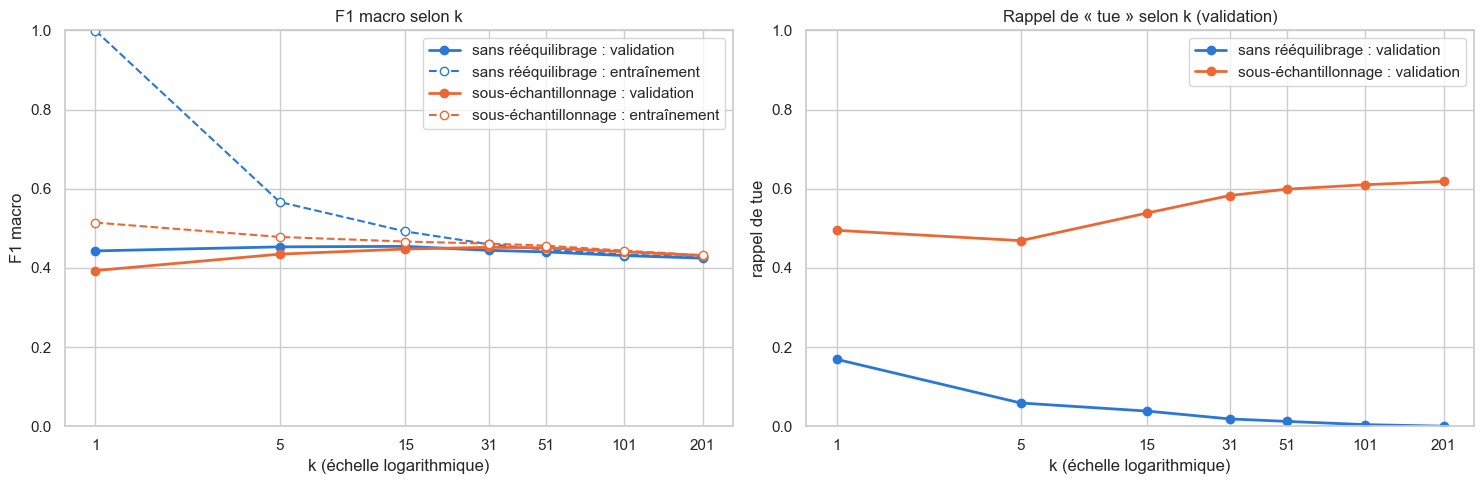

validation_f1_macro                      validation_rappel_tue  \
version  sans rééquilibrage sous-échantillonnage    sans rééquilibrage   
k                                                                        
1                     0.443                0.393                 0.169   
5                     0.453                0.435                 0.059   
15                    0.454                0.448                 0.038   
31                    0.444                0.452                 0.018   
51                    0.440                0.451                 0.012   
101                   0.431                0.441                 0.004   
201                   0.424                0.431                 0.000   

                              
version sous-échantillonnage  
k                             
1                      0.495  
5                      0.469  
15                     0.538  
31                     0.583  
51                     0.599  
101                    0.610  
201                    0.618

In [8]:
VALEURS_K = [1, 5, 15, 31, 51, 101, 201]
VERSIONS = {"sans rééquilibrage": None,
            "sous-échantillonnage": RandomUnderSampler(random_state=SEED)}
courbes = []
debut = time.time()
for version, reech in VERSIONS.items():
    for k in VALEURS_K:
        cv = cross_validate(pipeline(KNeighborsClassifier(n_neighbors=k), reech), X_train_fe, y_train, cv=CV,
                            scoring=METRIQUES, return_train_score=True, n_jobs=-1)
        courbes.append({"version": version, "k": k,
                        **{f"{jeu}_{m}": cv[f"{'test' if jeu == 'validation' else 'train'}_{m}"].mean()
                           for jeu in ["validation", "entraînement"] for m in METRIQUES}})
courbes = pd.DataFrame(courbes)
print(f"{len(courbes)} configurations en {time.time() - debut:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for version, couleur in zip(VERSIONS, ["#2a78d6", "#eb6834"]):
    c = courbes[courbes["version"] == version]
    axes[0].plot(c["k"], c["validation_f1_macro"], color=couleur, marker="o", lw=2, label=f"{version} : validation")
    axes[0].plot(c["k"], c["entraînement_f1_macro"], color=couleur, marker="o", lw=1.5, ls="--", mfc="white", label=f"{version} : entraînement")
    axes[1].plot(c["k"], c["validation_rappel_tue"], color=couleur, marker="o", lw=2, label=f"{version} : validation")
axes[0].set(title="F1 macro selon k", ylabel="F1 macro", ylim=(0, 1))
axes[1].set(title="Rappel de « tue » selon k (validation)", ylabel="rappel de tue", ylim=(0, 1))
for a in axes:
    a.set_xscale("log"); a.set_xticks(VALEURS_K, VALEURS_K); a.minorticks_off(); a.set_xlabel("k (échelle logarithmique)"); a.legend()
plt.tight_layout(); plt.show()
courbes.pivot(index="k", columns="version", values=["validation_f1_macro", "validation_rappel_tue"]).round(3)

**Lecture des courbes.**
- **Sans rééquilibrage** : avec *k* = 1, le score d'entraînement vaut 1 (chaque accident est son propre plus proche voisin) contre 0,44 en validation, ce qui est un sur-apprentissage maximal. Quand *k* augmente, les deux courbes se rejoignent (vers *k* ≈ 31) puis baissent ensemble : le modèle devient trop « moyen ». Surtout, **le rappel des tués s'effondre** (0,17 à *k* = 1, presque 0 au-delà de 50) : parmi 51 voisins, les tués ne sont presque jamais majoritaires.
- **Avec sous-échantillonnage**, le rappel des tués **monte** avec *k* (≈ 0,60 à partir de *k* = 51) et le F1 macro plafonne vers *k* = 31-51, sans sur-apprentissage.
- Remarque : pour les versions rééchantillonnées, le score « entraînement » est mesuré sur toute la partie entraînement du fold, y compris les accidents écartés par le sous-échantillonnage. C'est pourquoi il ne vaut pas 1 à *k* = 1.

### 5.2 Les trois versions, avec *k* = 51
*k* = 51 se situe dans la zone où le F1 macro de validation plafonne avec le sous-échantillonnage, et où le modèle ne sur-apprend presque plus (courbes ci-dessus).

In [9]:
K = 51
display(evaluer(f"KNN (k={K}), sans rééquilibrage", KNeighborsClassifier(n_neighbors=K)))
display(evaluer(f"KNN (k={K}), sous-échantillonnage", KNeighborsClassifier(n_neighbors=K), RandomUnderSampler(random_state=SEED)))
display(evaluer(f"KNN (k={K}), sur-échantillonnage", KNeighborsClassifier(n_neighbors=K), RandomOverSampler(random_state=SEED)))

KNN (k=51), sans rééquilibrage (11 s)


,validation,écart-type,entraînement
f1_macro,0.440,0.002,0.446
balanced_accuracy,0.444,0.002,0.450
rappel_tue,0.012,0.005,0.012
accuracy,0.702,0.002,0.709


KNN (k=51), sous-échantillonnage (3 s)


,validation,écart-type,entraînement
f1_macro,0.451,0.004,0.456
balanced_accuracy,0.535,0.003,0.543
rappel_tue,0.599,0.010,0.613
accuracy,0.572,0.005,0.577


KNN (k=51), sur-échantillonnage (19 s)


,validation,écart-type,entraînement
f1_macro,0.457,0.003,0.505
balanced_accuracy,0.534,0.004,0.612
rappel_tue,0.560,0.015,0.727
accuracy,0.569,0.003,0.604


### Comparaison avec les modèles précédents

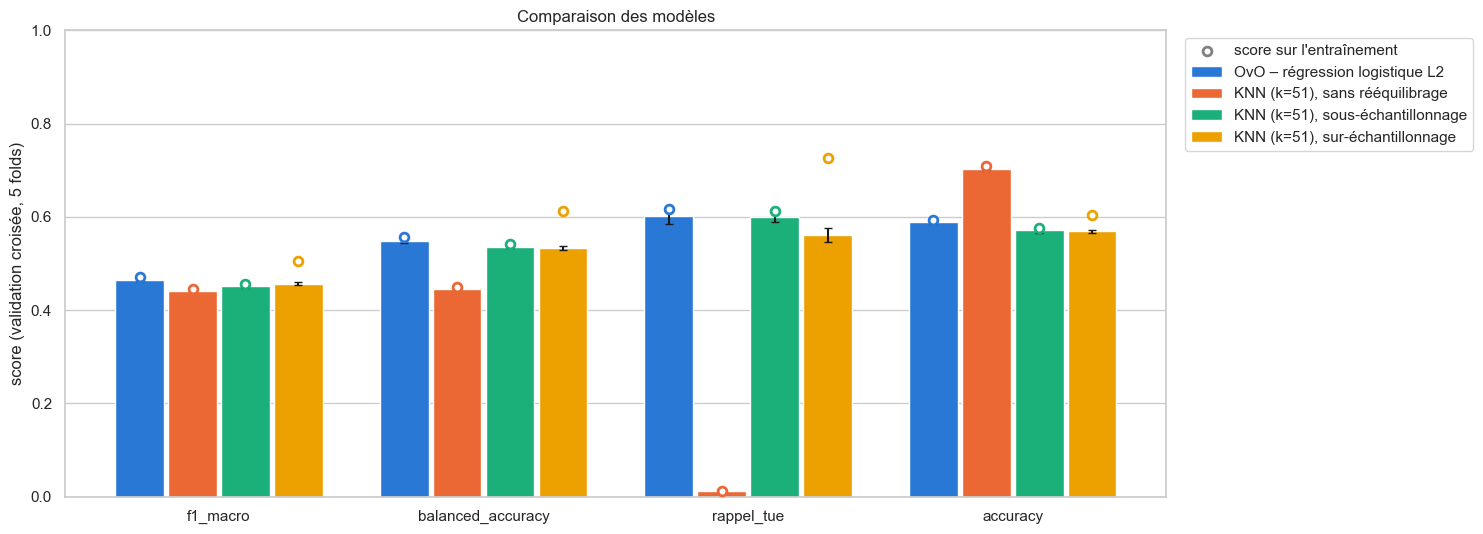

,f1_macro,balanced_accuracy,rappel_tue,accuracy
OvO – régression logistique L2,0.465,0.548,0.601,0.588
"KNN (k=51), sans rééquilibrage",0.440,0.444,0.012,0.702
"KNN (k=51), sous-échantillonnage",0.451,0.535,0.599,0.572
"KNN (k=51), sur-échantillonnage",0.457,0.534,0.560,0.569


In [10]:
comparer()

**Interprétation du KNN.**
- **Sans rééquilibrage, le modèle est inutilisable** malgré la meilleure accuracy de tous (0,70) : il ne détecte que **1 %** des accidents mortels. C'est l'illustration la plus nette du piège de l'accuracy sur des classes déséquilibrées.
- **Le sous-échantillonnage règle le problème** : rappel des tués ≈ 0,60, balanced accuracy 0,535, pour un train 6 fois plus petit, donc plus rapide. Le **sur-échantillonnage** donne un F1 macro à peine plus haut (0,457) mais **sur-apprend** : un tué dupliqué retrouve ses propres copies parmi ses voisins (rappel des tués de 0,73 sur l'entraînement contre 0,56 en validation), et il est 6 fois plus lent. Pour le KNN, **le sous-échantillonnage est le meilleur choix**.
- **Le KNN reste un peu en dessous de la régression logistique** sur toutes les métriques équilibrées. La distance euclidienne sur 78 colonnes est peu informative : chaque variable pèse autant dans la distance, qu'elle soit liée à la gravité ou non, et les colonnes one-hot ajoutent beaucoup de dimensions (*fléau de la dimension*). La logistique, elle, apprend un poids par variable.
- **Coût** : pas d'entraînement, mais chaque prédiction compare l'accident à tout le train : c'est le modèle le plus lent à prédire.
- Retenu comme représentant du KNN pour la suite : **KNN, *k* = 51, sous-échantillonnage**. Un réglage plus fin (*k*, pondération des voisins par la distance, choix des variables) pourrait gagner un peu, mais la limite vient surtout de la distance elle-même.

## 6. Classification multiclasse : One-vs-Rest (OvR) avec des SVM
### Principe
**SVM (Support Vector Machine)** : un classifieur **strictement binaire**. Il cherche la frontière qui sépare les deux classes avec la **plus grande marge** possible (la plus grande distance aux accidents les plus proches de chaque côté). Seuls les accidents proches de la frontière, ou mal classés, la déterminent : ce sont les **vecteurs de support**.
- **Noyau RBF** : au lieu d'une frontière droite (comme la logistique), le noyau gaussien permet des frontières **courbes**. C'est le moyen de tester si la non-linéarité aide, alors que la logistique sous-apprenait (section 4).
- **`C` = 1** : la régularisation. Un petit `C` tolère plus d'erreurs pour garder une marge large (modèle plus simple) ; un grand `C` colle davantage au train. **`gamma="scale"`** : la portée de l'influence de chaque accident, fixée d'après la variance des données. Valeurs par défaut : le réglage se fera par nested CV.

**One-vs-Rest** (l'autre stratégie du cours, après le One-vs-One de la section 4) : **un SVM par classe**, qui sépare cette classe de **toutes les autres réunies**, soit 3 SVM : `leger` contre le reste, `hospitalise` contre le reste, `tue` contre le reste. Chacun est entraîné sur **tous** les accidents. Pour prédire, on calcule les 3 scores (distance signée à chaque frontière) et on garde la classe dont le SVM est **le plus sûr**.

| | One-vs-One (section 4) | One-vs-Rest (ici) |
|---|---|---|
| Nombre de classifieurs | K(K−1)/2 = 3 | K = 3 |
| Données vues par chacun | les 2 classes de la paire | tout le train |
| Décision | vote | score le plus élevé |

(`SVC` utilise One-vs-One en interne par défaut ; on l'enveloppe dans `OneVsRestClassifier` pour imposer le One-vs-Rest.)

**Coût et déséquilibre.** Le temps d'entraînement d'un SVM à noyau croît environ comme le **carré** du nombre d'accidents : sur les ≈ 35 000 accidents de chaque fold, chaque SVM prendrait plusieurs minutes. On réutilise donc le **sous-échantillonnage** du KNN (≈ 6 150 accidents par fold, appliqué uniquement à la partie entraînement). Même après, chaque sous-problème OvR reste déséquilibré (une classe contre deux, soit 1/3 contre 2/3) : `class_weight="balanced"` compense à l'intérieur de chaque SVM.

In [11]:
svm_ovr = OneVsRestClassifier(SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced"))
evaluer("OvR – SVM RBF, sous-échantillonnage", svm_ovr, RandomUnderSampler(random_state=SEED))

OvR – SVM RBF, sous-échantillonnage (48 s)


,validation,écart-type,entraînement
f1_macro,0.479,0.002,0.507
balanced_accuracy,0.557,0.004,0.604
rappel_tue,0.586,0.010,0.699
accuracy,0.596,0.004,0.613


### Matrice de confusion
Même lecture qu'en section 4 : prédictions par validation croisée (mêmes 5 folds), lignes en % de la vraie classe.

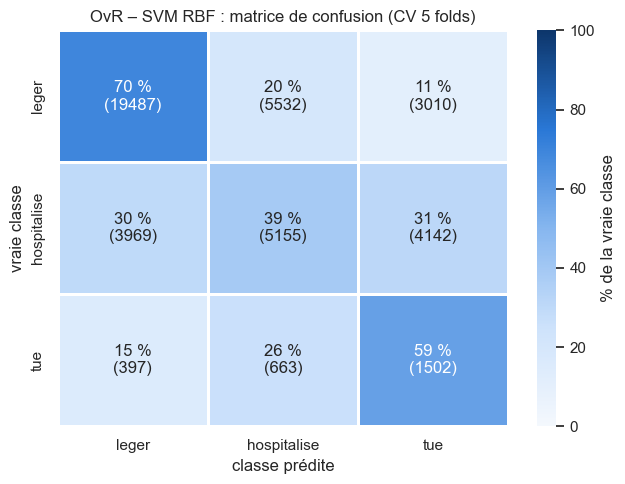

              precision    recall  f1-score   support

       leger      0.817     0.695     0.751     28029
 hospitalise      0.454     0.389     0.419     13266
         tue      0.174     0.586     0.268      2562

    accuracy                          0.596     43857
   macro avg      0.482     0.557     0.479     43857
weighted avg      0.670     0.596     0.622     43857



In [12]:
modele_svm = pipeline(svm_ovr, RandomUnderSampler(random_state=SEED))
y_pred_svm = cross_val_predict(modele_svm, X_train_fe, y_train, cv=CV, n_jobs=-1)

mc = confusion_matrix(y_train, y_pred_svm, labels=CLASSES)
mc_pct = pd.DataFrame(mc / mc.sum(axis=1, keepdims=True) * 100, index=CLASSES, columns=CLASSES)
annot = mc_pct.round(0).astype(int).astype(str) + " %\n(" + pd.DataFrame(mc, index=CLASSES, columns=CLASSES).astype(str) + ")"
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(mc_pct, annot=annot, fmt="", cmap=BLEUS, vmin=0, vmax=100, linewidths=2, linecolor="white",
            cbar_kws={"label": "% de la vraie classe"}, ax=ax)
ax.set(xlabel="classe prédite", ylabel="vraie classe", title="OvR – SVM RBF : matrice de confusion (CV 5 folds)")
plt.tight_layout(); plt.show()
print(classification_report(y_train, y_pred_svm, labels=CLASSES, digits=3))

### Les 3 SVM binaires
Ajusté sur tout le train (sous-échantillonné), le modèle contient bien 3 SVM, un par classe contre le reste. Le **nombre de vecteurs de support** mesure la difficulté de chaque séparation : plus il y a d'accidents près de la frontière ou du mauvais côté, plus le problème est difficile.

In [13]:
modele_svm.fit(X_train_fe, y_train)
n_train = sum(modele_svm[-2].fit_resample(modele_svm[:-2].transform(X_train_fe), y_train)[1].value_counts())
pd.DataFrame([{"SVM": f"{classe} contre le reste", "vecteurs de support": est.n_support_.sum(),
               "% des accidents d'entraînement": est.n_support_.sum() / n_train * 100}
              for classe, est in zip(modele_svm[-1].classes_, modele_svm[-1].estimators_)]).set_index("SVM").round(1)

,vecteurs de support,% des accidents d'entraînement
SVM,,
hospitalise contre le reste,6708,87.3
leger contre le reste,4845,63.0
tue contre le reste,5241,68.2


### Comparaison avec les modèles précédents

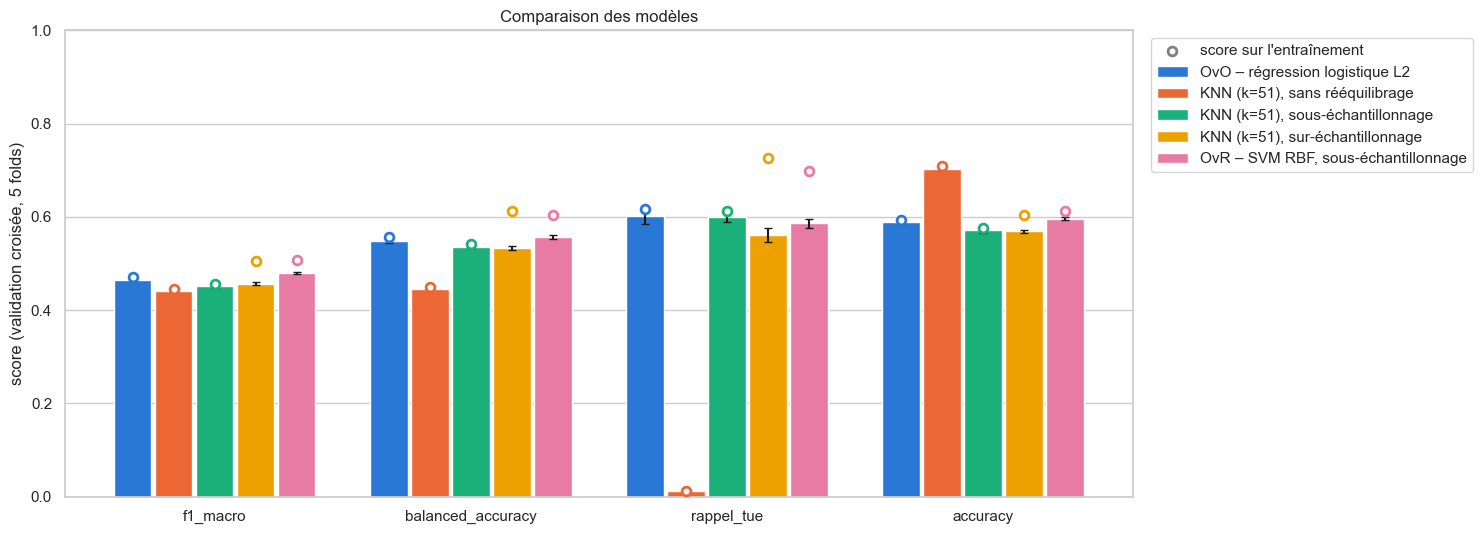

,f1_macro,balanced_accuracy,rappel_tue,accuracy
OvO – régression logistique L2,0.465,0.548,0.601,0.588
"KNN (k=51), sans rééquilibrage",0.440,0.444,0.012,0.702
"KNN (k=51), sous-échantillonnage",0.451,0.535,0.599,0.572
"KNN (k=51), sur-échantillonnage",0.457,0.534,0.560,0.569
"OvR – SVM RBF, sous-échantillonnage",0.479,0.557,0.586,0.596


In [14]:
comparer()

**Interprétation du SVM One-vs-Rest.**
- **Meilleur modèle à ce stade** sur les métriques équilibrées : F1 macro 0,479 et balanced accuracy 0,557, contre 0,465 et 0,548 pour la logistique OvO, alors qu'il n'est entraîné que sur ≈ 6 150 accidents par fold au lieu de 35 000. Les **frontières courbes du noyau RBF** apportent donc un peu, ce qui confirme le sous-apprentissage de la logistique.
- **Le gain vient surtout de `hospitalise`** : 39 % bien classés contre 34 % avec la logistique OvO ; le rappel des tués est presque identique (0,59 contre 0,60).
- **Léger sur-apprentissage** : F1 macro 0,507 sur l'entraînement contre 0,479 en validation, et surtout sur les tués (rappel 0,70 contre 0,59). Les tués sont tous gardés par le sous-échantillonnage, donc le modèle les a tous vus. Un `C` plus petit (plus de régularisation) pourrait réduire cet écart lors du réglage.
- **Vecteurs de support : 63 à 87 % des accidents d'entraînement**. Sur des classes bien séparées, seule une petite partie des points est près de la frontière. Ici, la plupart des accidents sont dans la marge ou du mauvais côté : les classes se **chevauchent fortement**, ce que montraient déjà l'ACP et le clustering du notebook 1. **`hospitalise` contre le reste est la séparation la plus difficile** (87 %), cohérent avec sa position de classe « du milieu ».
- **Comparer les stratégies OvO et OvR** : ici, le classifieur de base (logistique ou SVM) et le rééquilibrage changent aussi, donc l'écart ne vient pas de la stratégie seule. Pour isoler l'effet OvO / OvR, il faudrait le même classifieur dans les deux (par exemple `OneVsOneClassifier(SVC(...))` contre `OneVsRestClassifier(SVC(...))`).
- **Coût** : ≈ 50 s pour les 5 folds sur le train sous-échantillonné. Sur le train complet, ce serait de l'ordre de 25 fois plus long (coût quadratique) : le sous-échantillonnage est ici une nécessité pratique autant qu'une méthode de rééquilibrage.